Thiết bị: cpu
⚠️  Đang dùng CPU — ước tính ~15-20 phút

📋 Thông số cấu hình:
   Mô hình     : huawei-noah/TinyBERT_General_4L_312D
   Số mẫu      : 4000 (2000 mẫu/lớp)
   Độ dài tối đa: 64 | Kích thước lô: 32 | Số epoch: 3

Dữ liệu sau cân bằng: 4000 mẫu | Bình thường: 2000 | Tấn công: 2000
Trọng số lớp — Bình thường: 1.000 | Tấn công: 1.000
Huấn luyện: 2800 | Kiểm định: 600 | Kiểm tra: 600
Số lô mỗi epoch: 88


Loading weights: 100%|██████████| 71/71 [00:00<00:00, 4801.22it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: huawei-noah/TinyBERT_General_4L_312D
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.weight          | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
fit_denses.{0, 1, 2, 3, 4}.bias            | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:


🚀 Bắt đầu huấn luyện...
  Epoch 1 | Bước 10/88 | Mất mát: 0.6921
  Epoch 1 | Bước 20/88 | Mất mát: 0.6952
  Epoch 1 | Bước 30/88 | Mất mát: 0.6919
  Epoch 1 | Bước 40/88 | Mất mát: 0.6591
  Epoch 1 | Bước 50/88 | Mất mát: 0.6869
  Epoch 1 | Bước 60/88 | Mất mát: 0.6028
  Epoch 1 | Bước 70/88 | Mất mát: 0.6496
  Epoch 1 | Bước 80/88 | Mất mát: 0.5729

✅ Epoch 1/3 | Mất mát: 0.6529 | F1 Macro: 0.7172 | Recall Bình thường: 0.8200 | Recall Tấn công: 0.6200
   💾 Lưu mô hình tốt nhất (F1 Macro: 0.7172)

  Epoch 2 | Bước 10/88 | Mất mát: 0.5772
  Epoch 2 | Bước 20/88 | Mất mát: 0.6880
  Epoch 2 | Bước 30/88 | Mất mát: 0.5265
  Epoch 2 | Bước 40/88 | Mất mát: 0.4769
  Epoch 2 | Bước 50/88 | Mất mát: 0.5096
  Epoch 2 | Bước 60/88 | Mất mát: 0.4512
  Epoch 2 | Bước 70/88 | Mất mát: 0.5486
  Epoch 2 | Bước 80/88 | Mất mát: 0.4390

✅ Epoch 2/3 | Mất mát: 0.5313 | F1 Macro: 0.7912 | Recall Bình thường: 0.8400 | Recall Tấn công: 0.7433
   💾 Lưu mô hình tốt nhất (F1 Macro: 0.7912)

  Epoch 3 | Bước 

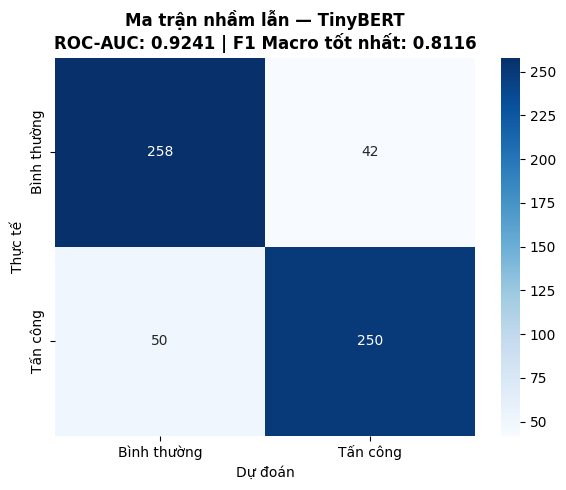

Đã lưu: ma_tran_nham_lan.png


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.26it/s]

✅ Đã lưu mô hình tại: ./tinybert_url


In [ ]:
# ====================================================
# TinyBERT — Phát hiện tấn công Web (URL)
# Tối ưu: cân bằng tốc độ & độ chính xác
# ====================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    roc_auc_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

thiet_bi = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Thiết bị: {thiet_bi}")
print("⚡ Đang dùng GPU!" if torch.cuda.is_available() else "⚠️  Đang dùng CPU — ước tính ~15-20 phút")

# ====================================================
# Cấu hình
# ====================================================
DUONG_DAN_DU_LIEU  = Path.cwd().parent / "Dataset" / "capec_small_multilabel2.csv"
TEN_MO_HINH        = "huawei-noah/TinyBERT_General_4L_312D"

DO_DAI_TOI_DA      = 64
KICH_THUOC_LO      = 32
SO_EPOCH           = 3
SO_MAU_MOI_LOP     = 2000   # 2000 bình thường + 2000 tấn công = 4000 tổng
TY_LE_HOC          = 3e-5
TY_LE_KHOI_DONG    = 0.1

print(f"\n📋 Thông số cấu hình:")
print(f"   Mô hình     : {TEN_MO_HINH}")
print(f"   Số mẫu      : {SO_MAU_MOI_LOP*2} ({SO_MAU_MOI_LOP} mẫu/lớp)")
print(f"   Độ dài tối đa: {DO_DAI_TOI_DA} | Kích thước lô: {KICH_THUOC_LO} | Số epoch: {SO_EPOCH}")

# ====================================================
# Đọc và cân bằng dữ liệu
# ====================================================
df       = pd.read_csv(DUONG_DAN_DU_LIEU, low_memory=False)
nhan     = (df['000 - Normal'] == 0).astype(int).values
urls     = df['request_http_request'].astype(str).values

# Lọc URL quá ngắn
bo_loc   = np.array([len(u.strip()) > 3 for u in urls])
urls     = urls[bo_loc]
nhan     = nhan[bo_loc]

du_lieu  = pd.DataFrame({"url": urls, "nhan": nhan})
binh_thuong = du_lieu[du_lieu["nhan"] == 0]
tan_cong    = du_lieu[du_lieu["nhan"] == 1]

binh_thuong_lay = resample(binh_thuong,
                            n_samples=min(SO_MAU_MOI_LOP, len(binh_thuong)),
                            random_state=SEED,
                            replace=len(binh_thuong) < SO_MAU_MOI_LOP)
tan_cong_lay    = resample(tan_cong,
                            n_samples=min(SO_MAU_MOI_LOP, len(tan_cong)),
                            random_state=SEED,
                            replace=len(tan_cong) < SO_MAU_MOI_LOP)

du_lieu_can_bang = pd.concat([binh_thuong_lay, tan_cong_lay]).sample(
    frac=1, random_state=SEED).reset_index(drop=True)

urls = du_lieu_can_bang["url"].values
nhan = du_lieu_can_bang["nhan"].values

print(f"\nDữ liệu sau cân bằng: {len(urls)} mẫu | Bình thường: {(nhan==0).sum()} | Tấn công: {(nhan==1).sum()}")

# ====================================================
# Trọng số lớp
# ====================================================
n0 = (nhan == 0).sum(); n1 = (nhan == 1).sum(); tong = len(nhan)
trong_so_lop = torch.tensor(
    [tong / (2 * n0), tong / (2 * n1)], dtype=torch.float
).to(thiet_bi)
print(f"Trọng số lớp — Bình thường: {trong_so_lop[0]:.3f} | Tấn công: {trong_so_lop[1]:.3f}")

# ====================================================
# Bộ dữ liệu
# ====================================================
bo_tach_tu = AutoTokenizer.from_pretrained(TEN_MO_HINH)

def lam_sach_url(url: str) -> str:
    """Tách các ký tự đặc biệt trong URL thành token riêng biệt."""
    for ky_tu in ['/', '?', '&', '=', '-', '_', '.', '%', '+']:
        url = url.replace(ky_tu, f' {ky_tu} ')
    return ' '.join(url.split())

class BoDuLieuURL(Dataset):
    def __init__(self, urls, nhan, bo_tach_tu, do_dai_toi_da):
        self.urls          = [lam_sach_url(u) for u in urls]
        self.nhan          = nhan
        self.bo_tach_tu    = bo_tach_tu
        self.do_dai_toi_da = do_dai_toi_da

    def __len__(self): return len(self.urls)

    def __getitem__(self, chi_so):
        ma_hoa = self.bo_tach_tu(
            self.urls[chi_so],
            truncation=True,
            padding='max_length',
            max_length=self.do_dai_toi_da,
            return_tensors='pt'
        )
        return {
            'input_ids':      ma_hoa['input_ids'].flatten(),
            'attention_mask': ma_hoa['attention_mask'].flatten(),
            'labels':         torch.tensor(self.nhan[chi_so], dtype=torch.long)
        }

# Chia tập dữ liệu 70 / 15 / 15
X_train, X_tam, y_train, y_tam = train_test_split(
    urls, nhan, test_size=0.3, random_state=SEED, stratify=nhan)
X_val, X_test, y_val, y_test = train_test_split(
    X_tam, y_tam, test_size=0.5, random_state=SEED, stratify=y_tam)

def tao_bo_tai(X, y, xao_tron):
    return DataLoader(
        BoDuLieuURL(X, y, bo_tach_tu, DO_DAI_TOI_DA),
        batch_size=KICH_THUOC_LO, shuffle=xao_tron, num_workers=0
    )

bo_tai_train = tao_bo_tai(X_train, y_train, xao_tron=True)
bo_tai_val   = tao_bo_tai(X_val,   y_val,   xao_tron=False)
bo_tai_test  = tao_bo_tai(X_test,  y_test,  xao_tron=False)

print(f"Huấn luyện: {len(X_train)} | Kiểm định: {len(X_val)} | Kiểm tra: {len(X_test)}")
print(f"Số lô mỗi epoch: {len(bo_tai_train)}")

# ====================================================
# Khởi tạo mô hình
# ====================================================
mo_hinh = AutoModelForSequenceClassification.from_pretrained(TEN_MO_HINH, num_labels=2)
mo_hinh.to(thiet_bi)

bo_toi_uu   = torch.optim.AdamW(mo_hinh.parameters(), lr=TY_LE_HOC, weight_decay=0.01)
tong_buoc   = len(bo_tai_train) * SO_EPOCH
lich_hoc    = get_linear_schedule_with_warmup(
    bo_toi_uu,
    num_warmup_steps=int(TY_LE_KHOI_DONG * tong_buoc),
    num_training_steps=tong_buoc
)
ham_mat_mat = nn.CrossEntropyLoss(weight=trong_so_lop, label_smoothing=0.1)

# ====================================================
# Vòng lặp huấn luyện
# ====================================================
lich_su    = {"mat_mat": [], "f1_macro": [], "recall_binh_thuong": [], "recall_tan_cong": []}
f1_tot_nhat   = 0.0
trang_thai_tot = None

print("\n🚀 Bắt đầu huấn luyện...")
for epoch in range(SO_EPOCH):
    # --- Huấn luyện ---
    mo_hinh.train()
    tong_mat_mat = 0
    for i, lo in enumerate(bo_tai_train):
        ids  = lo['input_ids'].to(thiet_bi)
        mask = lo['attention_mask'].to(thiet_bi)
        nhan_lo = lo['labels'].to(thiet_bi)

        bo_toi_uu.zero_grad()
        mat_mat = ham_mat_mat(mo_hinh(ids, attention_mask=mask).logits, nhan_lo)
        mat_mat.backward()
        torch.nn.utils.clip_grad_norm_(mo_hinh.parameters(), 1.0)
        bo_toi_uu.step()
        lich_hoc.step()
        tong_mat_mat += mat_mat.item()

        if (i + 1) % 10 == 0:
            print(f"  Epoch {epoch+1} | Bước {i+1}/{len(bo_tai_train)} | Mất mát: {mat_mat.item():.4f}")

    mat_mat_tb = tong_mat_mat / len(bo_tai_train)

    # --- Kiểm định ---
    mo_hinh.eval()
    du_doan_v, thuc_te_v = [], []
    with torch.no_grad():
        for lo in bo_tai_val:
            dau_ra = mo_hinh(
                lo['input_ids'].to(thiet_bi),
                attention_mask=lo['attention_mask'].to(thiet_bi)
            ).logits
            du_doan_v.extend(torch.argmax(dau_ra, dim=1).cpu().numpy())
            thuc_te_v.extend(lo['labels'].numpy())

    f1_macro = f1_score(thuc_te_v, du_doan_v, average="macro")
    rec_bt   = recall_score(thuc_te_v, du_doan_v, pos_label=0)
    rec_tc   = recall_score(thuc_te_v, du_doan_v, pos_label=1)

    lich_su["mat_mat"].append(mat_mat_tb)
    lich_su["f1_macro"].append(f1_macro)
    lich_su["recall_binh_thuong"].append(rec_bt)
    lich_su["recall_tan_cong"].append(rec_tc)

    print(f"\n✅ Epoch {epoch+1}/{SO_EPOCH} | Mất mát: {mat_mat_tb:.4f} | "
          f"F1 Macro: {f1_macro:.4f} | Recall Bình thường: {rec_bt:.4f} | Recall Tấn công: {rec_tc:.4f}")

    if f1_macro > f1_tot_nhat:
        f1_tot_nhat    = f1_macro
        trang_thai_tot = {k: v.clone() for k, v in mo_hinh.state_dict().items()}
        print(f"   💾 Lưu mô hình tốt nhất (F1 Macro: {f1_tot_nhat:.4f})")
    print()

# Tải lại mô hình tốt nhất
print(f"\n🏆 Tải mô hình tốt nhất (F1 Macro: {f1_tot_nhat:.4f})...")
mo_hinh.load_state_dict(trang_thai_tot)

# ====================================================
# Đánh giá trên tập kiểm tra
# ====================================================
mo_hinh.eval()
du_doan_t, thuc_te_t, xac_suat_t = [], [], []

with torch.no_grad():
    for lo in bo_tai_test:
        dau_ra = mo_hinh(
            lo['input_ids'].to(thiet_bi),
            attention_mask=lo['attention_mask'].to(thiet_bi)
        ).logits
        xac_suat_t.extend(torch.softmax(dau_ra, dim=1)[:, 1].cpu().numpy())
        du_doan_t.extend(torch.argmax(dau_ra, dim=1).cpu().numpy())
        thuc_te_t.extend(lo['labels'].numpy())

print("\n=== BÁO CÁO PHÂN LOẠI ===")
print(classification_report(thuc_te_t, du_doan_t, target_names=['Bình thường', 'Tấn công']))

diem_roc = roc_auc_score(thuc_te_t, xac_suat_t)
print(f"ROC-AUC: {diem_roc:.4f}")

# ====================================================
# Ma trận nhầm lẫn
# ====================================================
ma_tran = confusion_matrix(thuc_te_t, du_doan_t)

plt.figure(figsize=(6, 5))
sns.heatmap(
    ma_tran,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Bình thường", "Tấn công"],
    yticklabels=["Bình thường", "Tấn công"]
)
plt.title(f"Ma trận nhầm lẫn — TinyBERT\nROC-AUC: {diem_roc:.4f} | F1 Macro tốt nhất: {f1_tot_nhat:.4f}",
          fontsize=12, fontweight="bold")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.tight_layout()
plt.savefig("ma_tran_nham_lan.png", dpi=150, bbox_inches="tight")
plt.show()
print("Đã lưu: ma_tran_nham_lan.png")

# ====================================================
# Lưu mô hình
# ====================================================
mo_hinh.save_pretrained("./tinybert_url")
bo_tach_tu.save_pretrained("./tinybert_url")
print("✅ Đã lưu mô hình tại: ./tinybert_url")